# Rainfall in Australia: Statistical Modelling & Next-Day Rain Prediction

**Author:** Stylianos Stamatis · MSc Machine Learning (University of Thessaly), *Mathematical Modelling II* project

Daily observations from the Australian Bureau of Meteorology (`weatherAUS`, 49 stations, 2008–2017).
Tasks 1–10 focus on **Sydney**; Task 11 tests how a Sydney-trained classifier transfers to other climate zones.

| # | Task | Methods |
|---|------|---------|
| 1 | Exploratory analysis & distribution fitting | descriptive stats, Exponential / Gamma / Log-normal fits, KS test |
| 2 | Rain-day amount as Gamma(α, β) | method of moments, numerical MLE (digamma Newton), AIC |
| 3 | Probability of a rain day | Bayesian Beta–Bernoulli update vs. MLE / Wald CI |
| 4 | MaxTemp regression | OLS via normal equations, residual diagnostics, Breusch–Pagan |
| 5 | Next-day rain classifier | L2 logistic regression, stratified 5-fold CV |
| 6 | Evaluation & decision threshold | ROC / PR AUC, cost-weighted threshold selection |
| 7 | Model selection | AIC vs. BIC for nested logistic models |
| 8 | Weather regimes | Gaussian mixture model, BIC, adjusted Rand index |
| 9 | Extreme rainfall probability | analytic Gamma tail vs. Monte Carlo vs. empirical |
| 10 | Time series | ADF, ACF/PACF, ARIMA and seasonal SARIMA forecasts |
| 11 | Generalisation across climates | Sydney model on Darwin, Perth, Alice Springs; local retraining |

All random operations use `SEED = 42`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln, digamma, polygamma

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (adjusted_rand_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
RAIN_MM = 1.0   # a "rain day" has Rainfall > 1 mm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Data

The notebook reads `data/weatherAUS.csv`. If the file is missing it is downloaded from a public GitHub mirror
of the [Kaggle dataset](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package).

Two cleaning decisions matter for everything that follows:

* **`RISK_MM` is dropped.** Older copies of the dataset contain it; it is tomorrow's rainfall amount, i.e. the answer, so keeping it would leak the target.
* **Missing `Yes/No` values stay missing.** Encoding with `(col == "Yes").astype(int)` silently turns a missing label into `0` ("no rain"). Mapping `Yes→1, No→0` keeps them as `<NA>` so they can be dropped explicitly.

In [2]:
DATA_PATH = ROOT / "data" / "weatherAUS.csv"
MIRROR_URL = "https://raw.githubusercontent.com/amankharwal/Website-data/master/weatherAUS.csv"

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    pd.read_csv(MIRROR_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.drop(columns=["RISK_MM"], errors="ignore")
df = df.sort_values(["Location", "Date"]).reset_index(drop=True)
for col in ["RainToday", "RainTomorrow"]:
    df[col] = df[col].map({"Yes": 1, "No": 0}).astype("Int64")

syd = df[df["Location"] == "Sydney"].set_index("Date").sort_index()

print(f"All stations: {df.shape[0]:,} rows, {df['Location'].nunique()} stations")
print(f"Sydney: {len(syd):,} rows, {syd.index.min().date()} → {syd.index.max().date()}")
syd.isna().mean().mul(100).round(1).sort_values(ascending=False).head(6).rename("% missing (Sydney)")

All stations: 142,193 rows, 49 stations
Sydney: 3,337 rows, 2008-02-01 → 2017-06-25


WindGustSpeed    31.0
WindGustDir      31.0
Cloud9am         17.0
Cloud3pm         16.8
WindDir9am        1.7
Evaporation       1.5
Name: % missing (Sydney), dtype: float64

## Task 1 — Exploratory analysis and distribution fitting

Rows missing a variable are dropped only for that variable.

In [3]:
def describe(x):
    x = x.dropna()
    return {"n": len(x), "mean": x.mean(), "std": x.std(), "skew": x.skew(), "kurtosis": x.kurtosis()}

pd.DataFrame({"MaxTemp (°C)": describe(syd["MaxTemp"]),
              "Rainfall (mm)": describe(syd["Rainfall"])}).T.round(3)

,n,mean,std,skew,kurtosis
MaxTemp (°C),3335.0,23.002,4.495,0.509,0.555
Rainfall (mm),3331.0,3.330,9.895,5.366,37.440


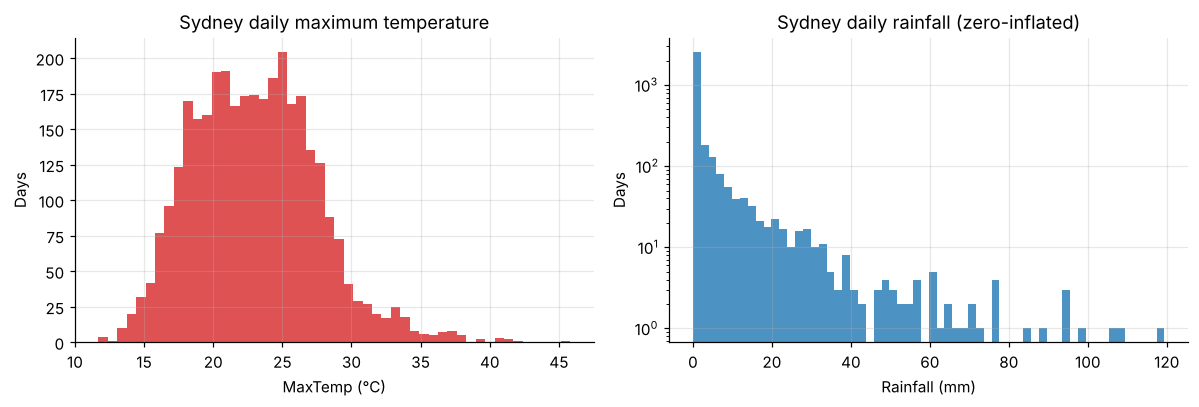

Share of days with exactly 0 mm: 60.7%
Rain days (> 1.0 mm): 26.0% of 3,331 days


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(syd["MaxTemp"].dropna(), bins=50, color="tab:red", alpha=0.8)
ax[0].set(title="Sydney daily maximum temperature", xlabel="MaxTemp (°C)", ylabel="Days")
ax[1].hist(syd["Rainfall"].dropna(), bins=60, color="tab:blue", alpha=0.8)
ax[1].set(title="Sydney daily rainfall (zero-inflated)", xlabel="Rainfall (mm)", ylabel="Days", yscale="log")
plt.tight_layout(); save("t1_distributions"); plt.show()

rain_obs = syd["Rainfall"].dropna()
rain_day_frac = (rain_obs > RAIN_MM).mean()
print(f"Share of days with exactly 0 mm: {(rain_obs == 0).mean():.1%}")
print(f"Rain days (> {RAIN_MM} mm): {rain_day_frac:.1%} of {len(rain_obs):,} days")

### Rainfall amount on rain days

On rain days the amounts are strongly right-skewed. Three candidate distributions are fitted by maximum likelihood (location fixed at 0) and compared with the Kolmogorov–Smirnov statistic
$D = \sup_x |\hat F_n(x) - F(x;\hat\theta)|$.

In [5]:
wet = syd.loc[syd["Rainfall"] > RAIN_MM, "Rainfall"].to_numpy(dtype=float)
print(pd.Series(describe(pd.Series(wet))).round(3).to_string())

fits = {
    "Exponential": (stats.expon, stats.expon.fit(wet, floc=0)),
    "Gamma": (stats.gamma, stats.gamma.fit(wet, floc=0)),
    "Log-normal": (stats.lognorm, stats.lognorm.fit(wet, floc=0)),
}
ks_rows = []
for name, (dist, params) in fits.items():
    ks = stats.kstest(wet, dist.cdf, args=params)
    ks_rows.append({"distribution": name, "params": np.round(params, 4), "KS D": ks.statistic, "p-value": ks.pvalue})
ks_table = pd.DataFrame(ks_rows).set_index("distribution")
ks_table

n           866.000
mean         12.597
std          16.145
skew          2.873
kurtosis     10.343


,params,KS D,p-value
distribution,,,
Exponential,"[0.0, 12.5975]",0.1113,8.4486e-10
Gamma,"[0.9933, 0.0, 12.6819]",0.1100,1.3724e-09
Log-normal,"[1.061, 0.0, 7.0424]",0.0555,9.2897e-03


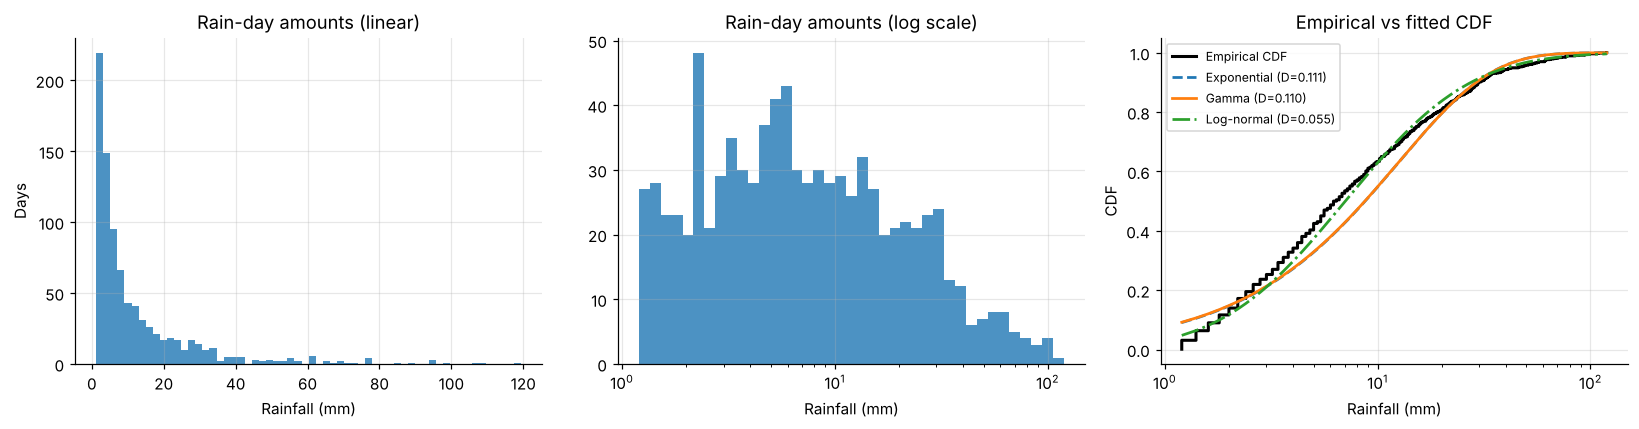

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(wet, bins=60, color="tab:blue", alpha=0.8)
ax[0].set(title="Rain-day amounts (linear)", xlabel="Rainfall (mm)", ylabel="Days")
ax[1].hist(wet, bins=np.logspace(np.log10(wet.min()), np.log10(wet.max()), 40), color="tab:blue", alpha=0.8)
ax[1].set(title="Rain-day amounts (log scale)", xlabel="Rainfall (mm)", xscale="log")

xs = np.sort(wet)
ax[2].step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color="black", lw=2, label="Empirical CDF")
for (name, (dist, params)), ls in zip(fits.items(), ["--", "-", "-."]):
    ax[2].plot(xs, dist.cdf(xs, *params), ls, lw=1.8, label=f"{name} (D={ks_table.loc[name, 'KS D']:.3f})")
ax[2].set(title="Empirical vs fitted CDF", xlabel="Rainfall (mm)", ylabel="CDF", xscale="log")
ax[2].legend(fontsize=8)
plt.tight_layout(); save("t1_rainday_fits"); plt.show()

### Seasonality

Monthly **rain-day frequency** (share of days with > 1 mm) and monthly mean MaxTemp, averaged over all years.

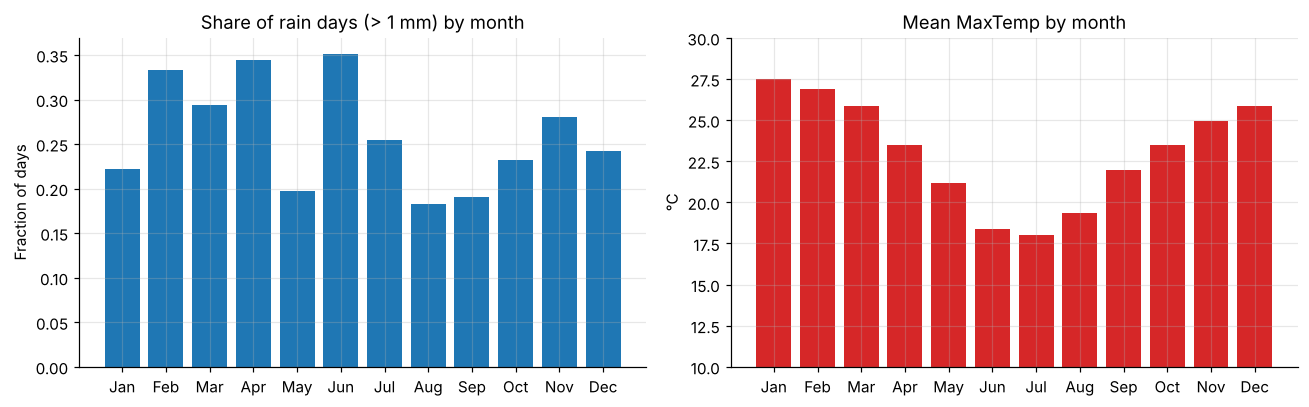

Max/min monthly ratio — rain-day frequency: 1.92, MaxTemp: 1.53


,rain_day_frac,mean_rain_mm,mean_maxtemp,rain_days_per_month
Jan,0.222,3.128,27.517,6.889
Feb,0.333,4.324,26.881,9.417
Mar,0.294,4.484,25.881,9.100
Apr,0.344,5.195,23.504,10.333
May,0.197,2.434,21.154,6.100
Jun,0.352,5.852,18.373,10.546
Jul,0.254,2.853,17.991,7.889
Aug,0.183,2.156,19.342,5.667
Sep,0.190,1.825,21.994,5.709
Oct,0.232,2.180,23.461,7.188


In [7]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = pd.DataFrame({
    "rain_day_frac": (rain_obs > RAIN_MM).groupby(rain_obs.index.month).mean(),
    "mean_rain_mm": rain_obs.groupby(rain_obs.index.month).mean(),
    "mean_maxtemp": syd["MaxTemp"].groupby(syd.index.month).mean(),
})
monthly.index = MONTHS
monthly["rain_days_per_month"] = monthly["rain_day_frac"] * pd.Series(
    [31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=MONTHS)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(MONTHS, monthly["rain_day_frac"], color="tab:blue")
ax[0].set(title="Share of rain days (> 1 mm) by month", ylabel="Fraction of days")
ax[1].bar(MONTHS, monthly["mean_maxtemp"], color="tab:red")
ax[1].set(title="Mean MaxTemp by month", ylabel="°C", ylim=(10, 30))
plt.tight_layout(); save("t1_seasonality"); plt.show()

amp = monthly.max() / monthly.min()
print(f"Max/min monthly ratio — rain-day frequency: {amp['rain_day_frac']:.2f}, MaxTemp: {amp['mean_maxtemp']:.2f}")
monthly.round(3)

**Interpretation**

* **MaxTemp** is close to Gaussian: mean ≈ 23.0 °C, sd ≈ 4.5 °C, skewness 0.51, excess kurtosis 0.56. The slight right skew comes from a few hot-westerly summer days.
* **Rainfall** is extremely zero-inflated. 61% of days record exactly 0 mm, skewness is 5.4 and kurtosis 37: most days are dry, and a few storms dominate the totals.
* **26.0% of days are rain days** (> 1 mm), inside the expected 25–30% for Sydney.
* **On rain days**, amounts average 12.6 mm with a long right tail (max ≈ 120 mm). The **log-normal fits best** (KS D = 0.056, against ≈ 0.11 for the Exponential and Gamma). All three are still rejected at 5% with n = 866, which is common with large samples. Anchored at 0 mm, the Gamma MLE has α ≈ 0.99, so it is practically the Exponential. Task 2 explains why.
* **Seasonality.** Temperature has a clean annual cycle, from 27.5 °C in January to 18.0 °C in July. The rain-day frequency is noisier and weaker. It peaks in June (35% of days, ≈ 10.5 rain days) and in April and February. The driest months are August and September (≈ 18–19%, ≈ 5.7 days). The June peak matches the East Coast Low season, and the February peak matches summer thunderstorms. Rainfall seasonality is weaker than temperature seasonality, as expected for a temperate climate.

## Task 2 — Rain-day amounts as Gamma(α, β)

Parametrisation: $\mathbb E[X]=\alpha/\beta$, $\operatorname{Var}(X)=\alpha/\beta^2$.

**Method of moments.** Setting $\bar X = \alpha/\beta$ and $s^2 = \alpha/\beta^2$ and dividing the first by the second gives $\beta = \bar X / s^2$; substituting back, $\alpha = \beta\bar X$:

$$\hat\alpha_{\text{MoM}} = \frac{\bar X^2}{s^2}, \qquad \hat\beta_{\text{MoM}} = \frac{\bar X}{s^2}.$$

**Maximum likelihood.** The log-likelihood is
$\ell(\alpha,\beta) = n\alpha\log\beta - n\log\Gamma(\alpha) + (\alpha-1)\sum\log x_i - \beta\sum x_i$.
From $\partial\ell/\partial\beta = 0$: $\beta = \alpha/\bar X$. Substituting into $\partial\ell/\partial\alpha = 0$ gives an equation with no closed form,

$$\log\alpha - \psi(\alpha) = \log\bar X - \overline{\log X},$$

solved here with Newton's method ($\psi$ = digamma, $\psi'$ = trigamma).

**Exponential** (Gamma with α = 1): $\hat\beta_{\text{Exp}} = 1/\bar X$.

**Why MLE matters for AIC.** AIC $= 2k - 2\ell(\hat\theta)$ assumes $\hat\theta$ maximises the likelihood. Plugging in moment estimates understates the Gamma's best achievable fit; since the Exponential is a special case of the Gamma, the Gamma MLE log-likelihood can never be lower than the Exponential's.

In [8]:
x = wet
n, xbar, s2 = len(x), x.mean(), x.var(ddof=0)
mean_log = np.log(x).mean()

def gamma_loglik(a, b, x):
    return np.sum(a * np.log(b) - gammaln(a) + (a - 1) * np.log(x) - b * x)

def gamma_mle(x, tol=1e-12, max_iter=100):
    # Newton's method on log(a) - digamma(a) = log(mean x) - mean(log x)
    c = np.log(x.mean()) - np.log(x).mean()
    a = 0.5 / c                      # standard starting value
    for _ in range(max_iter):
        step = (np.log(a) - digamma(a) - c) / (1 / a - polygamma(1, a))
        a -= step
        if abs(step) < tol:
            break
    return a, a / x.mean()

a_mom, b_mom = xbar**2 / s2, xbar / s2
a_mle, b_mle = gamma_mle(x)
b_exp = 1 / xbar

rows = [
    ("Exponential (MLE)", 1, 1.0, b_exp, gamma_loglik(1.0, b_exp, x)),
    ("Gamma (MoM)", 2, a_mom, b_mom, gamma_loglik(a_mom, b_mom, x)),
    ("Gamma (MLE)", 2, a_mle, b_mle, gamma_loglik(a_mle, b_mle, x)),
]
t2 = pd.DataFrame(rows, columns=["model", "k", "alpha", "beta", "logL"]).set_index("model")
t2["AIC"] = 2 * t2["k"] - 2 * t2["logL"]
t2["ΔAIC vs Exp"] = t2["AIC"] - t2.loc["Exponential (MLE)", "AIC"]

print(f"n = {n}, mean = {xbar:.3f} mm, variance = {s2:.2f}")
print(f"Check vs scipy.stats.gamma.fit: alpha = {fits['Gamma'][1][0]:.4f}")
t2.round(4)

n = 866, mean = 12.597 mm, variance = 260.35
Check vs scipy.stats.gamma.fit: alpha = 0.9933


,k,alpha,beta,logL,AIC,ΔAIC vs Exp
model,,,,,,
Exponential (MLE),1,1.0000,0.0794,-3060.0068,6122.0136,0.0000
Gamma (MoM),2,0.6096,0.0484,-3118.8225,6241.6451,119.6314
Gamma (MLE),2,0.9933,0.0789,-3059.9943,6123.9886,1.9750


### Sensitivity: the 1 mm threshold

Rain days are defined as > 1 mm, so the data are **left-truncated at 1 mm** while the Gamma above is anchored at 0.
Fitting the *excess* $Y = X - 1$ removes this artefact.

In [9]:
y_exc = x - RAIN_MM
a_exc, b_exc = gamma_mle(y_exc)
ll_g_exc = gamma_loglik(a_exc, b_exc, y_exc)
ll_e_exc = gamma_loglik(1.0, 1 / y_exc.mean(), y_exc)
print(f"Excess over 1 mm: Gamma MLE alpha = {a_exc:.4f}, beta = {b_exc:.4f}")
print(f"AIC Gamma = {4 - 2*ll_g_exc:.2f}, AIC Exponential = {2 - 2*ll_e_exc:.2f}, "
      f"ΔAIC (Gamma − Exp) = {(4 - 2*ll_g_exc) - (2 - 2*ll_e_exc):.2f}")

Excess over 1 mm: Gamma MLE alpha = 0.7332, beta = 0.0632
AIC Gamma = 5918.64, AIC Exponential = 5978.76, ΔAIC (Gamma − Exp) = -60.12


**Interpretation**

* The **method of moments gives α̂ = 0.61**, which is < 1 and inside the range the brief expected. α̂/β̂ = 12.6 mm reproduces the sample mean exactly.
* Plugged into the likelihood, however, the MoM estimates fit badly. Their log-likelihood is 59 units **lower** than the Exponential's, so AIC appears to prefer the Exponential by 120. **This is an artefact of using non-ML estimates in AIC**, not evidence against the Gamma. MoM matches the variance, which is dominated by a handful of extreme days, and that pushes α too low.
* The **numerical MLE** gives α̂ = 0.993 (Newton's method agrees with `scipy.stats.gamma.fit` to 4 decimals). Its log-likelihood is only 0.01 above the Exponential's, so ΔAIC = +1.98 and the Exponential wins on parsimony. With a Gamma anchored at 0 mm, the data offer no evidence against a constant hazard rate.
* **The 1 mm threshold changes this.** Rain days start at 1 mm, not at 0 mm. Fitting the excess over 1 mm gives **α̂ = 0.73 and ΔAIC = −60 in favour of the Gamma**. Once the truncation is handled, the expected picture appears: many light-rain days, a long heavy tail, and a hazard that falls with the amount.
* **Takeaway:** compare models with AIC using maximum-likelihood fits, and define the support of the model to match how the data were selected.

## Task 3 — Bayesian estimate of the rain-day probability

Each day is Bernoulli(θ). With $n_1$ rain days and $n_0$ dry days the likelihood is $L(\theta)\propto\theta^{n_1}(1-\theta)^{n_0}$.
The Bureau of Meteorology's long-run Sydney climatology (≈ 0.30) is encoded as a Beta(15, 35) prior — mean 0.30, worth 50 pseudo-days.
Since $p(\theta\mid\text{data}) \propto \theta^{n_1+\alpha_0-1}(1-\theta)^{n_0+\beta_0-1}$, the posterior is $\text{Beta}(\alpha_0+n_1,\ \beta_0+n_0)$.

In [10]:
n_all = len(rain_obs)
n1 = int((rain_obs > RAIN_MM).sum()); n0 = n_all - n1
a0, b0 = 15, 35
a_post, b_post = a0 + n1, b0 + n0

theta_mle = n1 / n_all
theta_post = a_post / (a_post + b_post)
cred = stats.beta.ppf([0.025, 0.975], a_post, b_post)
se = np.sqrt(theta_mle * (1 - theta_mle) / n_all)
wald = theta_mle + np.array([-1.96, 1.96]) * se

print(f"n = {n_all}, rain days n1 = {n1}, dry days n0 = {n0}")
print(f"Prior Beta({a0},{b0}): mean {a0/(a0+b0):.3f}, sd {np.sqrt(a0*b0/((a0+b0)**2*(a0+b0+1))):.4f}")
print(f"Posterior Beta({a_post},{b_post}): mean {theta_post:.4f}, 95% credible [{cred[0]:.4f}, {cred[1]:.4f}]")
print(f"MLE {theta_mle:.4f}, 95% Wald CI [{wald[0]:.4f}, {wald[1]:.4f}]")
print(f"Shift posterior − MLE = {theta_post - theta_mle:+.4f} ({(theta_post - theta_mle)/theta_mle:+.2%} of the MLE)")

n = 3331, rain days n1 = 866, dry days n0 = 2465
Prior Beta(15,35): mean 0.300, sd 0.0642
Posterior Beta(881,2500): mean 0.2606, 95% credible [0.2459, 0.2755]
MLE 0.2600, 95% Wald CI [0.2451, 0.2749]
Shift posterior − MLE = +0.0006 (+0.23% of the MLE)


**Interpretation**

* The data contain n₁ = 866 rain days out of n = 3,331 (MLE θ̂ = 0.260). The posterior mean is 0.2606, with a 95% credible interval of [0.246, 0.276].
* The prior's 50 pseudo-days are overwhelmed by 3,331 real days. The posterior moves only **+0.0006 (+0.23%) from the MLE**, and the credible and Wald intervals almost coincide. The brief expected a shift of ~1–2%. The actual shift is smaller because the prior mean (0.30) is not far from the data and the sample is large.
* The 2008–2017 decade was a little drier than the long-run climatology (26% against 30% rain days), and the data, not the prior, decide the estimate. A prior would matter for a new station with only a few weeks of records.

## Task 4 — Linear regression for MaxTemp

Model $y = X\beta + \varepsilon$ with standardised predictors MinTemp, Sunshine, WindGustSpeed.
Minimising $S(\beta) = (y-X\beta)^\top(y-X\beta)$ gives $\partial S/\partial\beta = -2X^\top(y - X\beta) = 0$, i.e. the **normal equations** $X^\top X\,\hat\beta = X^\top y$.
Standard errors: $\operatorname{se}(\hat\beta_j) = \sqrt{\hat\sigma^2[(X^\top X)^{-1}]_{jj}}$ with $\hat\sigma^2 = \text{RSS}/(n-p)$.

WindGustSpeed is missing on ~31% of Sydney days, so the regression uses complete cases only.

In [11]:
cols4 = ["MaxTemp", "MinTemp", "Sunshine", "WindGustSpeed"]
d4 = syd[cols4].dropna()
y4 = d4["MaxTemp"].to_numpy()
Z = d4[cols4[1:]].to_numpy()
Z = (Z - Z.mean(0)) / Z.std(0)
X4 = np.column_stack([np.ones(len(Z)), Z])

beta = np.linalg.solve(X4.T @ X4, X4.T @ y4)
fitted = X4 @ beta
resid = y4 - fitted
n4, p4 = X4.shape
sigma2 = resid @ resid / (n4 - p4)
se_b = np.sqrt(np.diag(sigma2 * np.linalg.inv(X4.T @ X4)))
r2 = 1 - resid @ resid / np.sum((y4 - y4.mean())**2)

ols = pd.DataFrame({"coef": beta, "std err": se_b, "t": beta / se_b},
                   index=["Intercept", "MinTemp (std)", "Sunshine (std)", "WindGustSpeed (std)"])
print(f"Complete cases: {n4} of {len(syd)} Sydney days;  R² = {r2:.4f};  residual sd = {np.sqrt(sigma2):.2f} °C")

# Breusch–Pagan: regress squared residuals on the predictors, LM = n·R²_aux ~ χ²(p−1)
u = resid**2
g = np.linalg.lstsq(X4, u, rcond=None)[0]
r2_aux = 1 - np.sum((u - X4 @ g)**2) / np.sum((u - u.mean())**2)
lm = n4 * r2_aux
print(f"Breusch–Pagan LM = {lm:.2f}, p = {stats.chi2.sf(lm, df=p4 - 1):.2e}")
ols.round(4)

Complete cases: 2289 of 3337 Sydney days;  R² = 0.7360;  residual sd = 2.30 °C
Breusch–Pagan LM = 169.15, p = 1.95e-36


,coef,std err,t
Intercept,23.2851,0.0480,484.8282
MinTemp (std),3.5666,0.0487,73.2390
Sunshine (std),1.7027,0.0482,35.3536
WindGustSpeed (std),-0.0999,0.0486,-2.0556


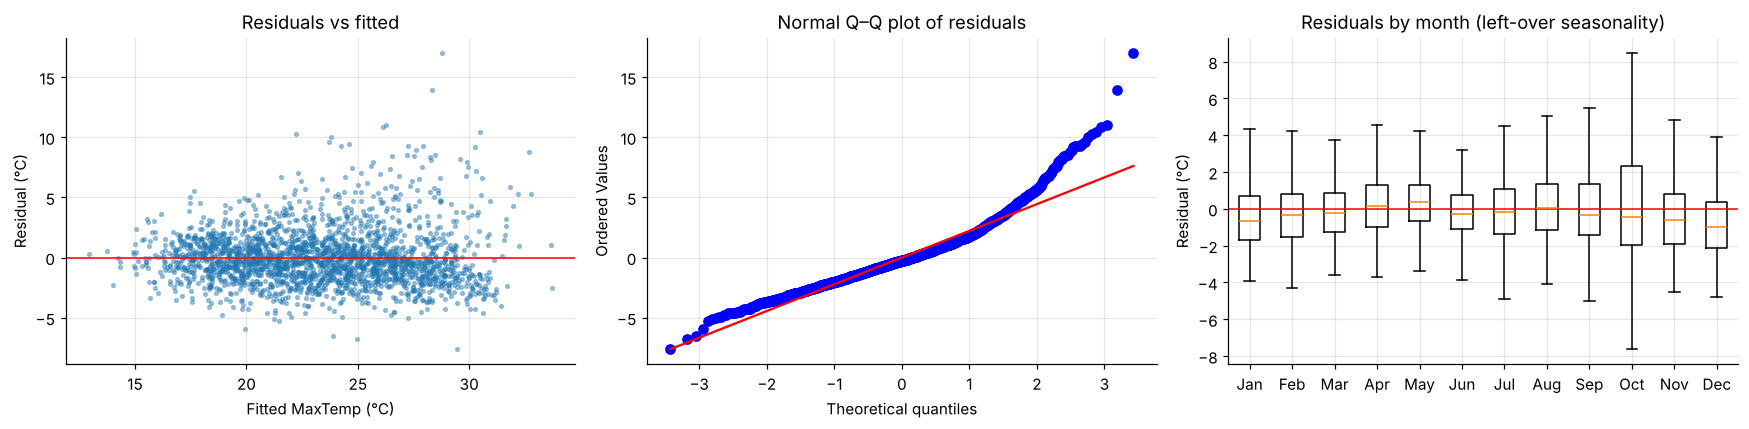

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(fitted, resid, s=6, alpha=0.4)
ax[0].axhline(0, color="red", lw=1)
ax[0].set(title="Residuals vs fitted", xlabel="Fitted MaxTemp (°C)", ylabel="Residual (°C)")
stats.probplot(resid, dist="norm", plot=ax[1])
ax[1].set_title("Normal Q–Q plot of residuals")
by_month = [resid[d4.index.month == m] for m in range(1, 13)]
ax[2].boxplot(by_month, tick_labels=MONTHS, showfliers=False)
ax[2].axhline(0, color="red", lw=1)
ax[2].set(title="Residuals by month (left-over seasonality)", ylabel="Residual (°C)")
plt.tight_layout(); save("t4_residuals"); plt.show()

**Interpretation** (n = 2,289 complete cases, R² = 0.736, residual sd 2.3 °C)

* **MinTemp (+3.57 °C per sd, t = 73)** is by far the strongest predictor. A warm night and a warm day reflect the same air mass.
* **Sunshine (+1.70 °C per sd, t = 35)**: clear skies allow more radiative heating.
* **WindGustSpeed (−0.10 °C per sd, t = −2.1)** is weak and barely significant. The unsigned gust speed mixes hot-dry westerlies (warming) with cool southerly changes and sea breezes (cooling), and the two effects cancel.
* **Diagnostics.** Breusch–Pagan LM = 169 (p ≈ 10⁻³⁶) rejects constant variance. The Q–Q plot shows a heavy right tail, i.e. the model under-predicts the hottest days (westerly heatwaves). The residuals-by-month plot shows **leftover seasonality**. Median residuals are negative in November–January (the model over-predicts early-summer days, when cool sea breezes and southerly changes cap the temperature) and slightly positive in April–May. The spread is widest in September–October, the season of hot spring westerlies. The meteorological predictors therefore do not capture the full annual cycle, so adding month or season terms would be a natural next step.

## Task 5 — Logistic regression for RainTomorrow

**Loss.** With $p_i = \sigma(\beta^\top x_i)$ and $y_i\sim\text{Bernoulli}(p_i)$, the likelihood is $\prod_i p_i^{y_i}(1-p_i)^{1-y_i}$.
Taking the negative log gives the cross-entropy loss, and the L2 penalty adds $\tfrac{1}{2C}\lVert\beta\rVert^2$ (with $C = 1/\lambda$):

$$\mathcal L(\beta) = -\sum_i\big[y_i\log p_i + (1-y_i)\log(1-p_i)\big] + \frac{1}{2C}\sum_j\beta_j^2 .$$

**Preprocessing choices**
* Rows with missing `RainTomorrow` are dropped; `Cloud9am` / `Cloud3pm` are dropped (≈ 17% missing in Sydney).
* Remaining numeric gaps (incl. Evaporation, Sunshine) are **median-imputed**, then standardised — both fitted on the training set only, inside a pipeline, so no test information leaks into preprocessing.
* Wind directions (16 compass points × 3 columns) are one-hot encoded with one reference level dropped.
* Stratified 80/20 split; C is tuned by stratified 5-fold CV on log-loss.

In [13]:
WIND = ["WindGustDir", "WindDir9am", "WindDir3pm"]
DROP = ["Location", "Cloud9am", "Cloud3pm"]

def make_xy(frame):
    frame = frame[frame["RainTomorrow"].notna()]
    X = pd.get_dummies(frame.drop(columns=DROP + ["RainTomorrow"], errors="ignore"),
                       columns=WIND, drop_first=True, dtype=float)
    return X, frame["RainTomorrow"].astype(int)

X_syd, y_syd = make_xy(syd)
NUMERIC = [c for c in X_syd.columns if not c.startswith(tuple(WIND))]
DUMMIES = [c for c in X_syd.columns if c not in NUMERIC]

def make_pipeline(model):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("dummies", "passthrough", DUMMIES),
    ])
    return Pipeline([("pre", pre), ("clf", model)])

X_tr, X_te, y_tr, y_te = train_test_split(X_syd, y_syd, test_size=0.20, stratify=y_syd, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

clf = make_pipeline(LogisticRegressionCV(Cs=np.logspace(-4, 2, 25), cv=cv, l1_ratios=(0.0,),
                                         scoring="neg_log_loss", max_iter=5000))
clf.fit(X_tr, y_tr)
best_C = float(clf.named_steps["clf"].C_[0])

coef = pd.Series(clf.named_steps["clf"].coef_[0], index=NUMERIC + DUMMIES)
coef_num = coef[NUMERIC].sort_values(key=np.abs, ascending=False)
print(f"Rows: {len(X_syd)} (train {len(X_tr)}, test {len(X_te)}); positive rate {y_syd.mean():.1%}")
print(f"Features: {len(NUMERIC)} numeric + {len(DUMMIES)} wind dummies")
print(f"Best C = {best_C:.4f}  (λ = 1/C = {1/best_C:.2f})")
coef_num.head(8).round(3).rename("standardised coefficient")

Rows: 3337 (train 2669, test 668); positive rate 25.9%
Features: 15 numeric + 45 wind dummies
Best C = 0.1000  (λ = 1/C = 10.00)


Humidity3pm      0.904
Sunshine        -0.901
MinTemp         -0.602
MaxTemp          0.368
WindGustSpeed    0.316
Temp9am          0.268
RainToday        0.215
Pressure3pm     -0.139
Name: standardised coefficient, dtype: float64

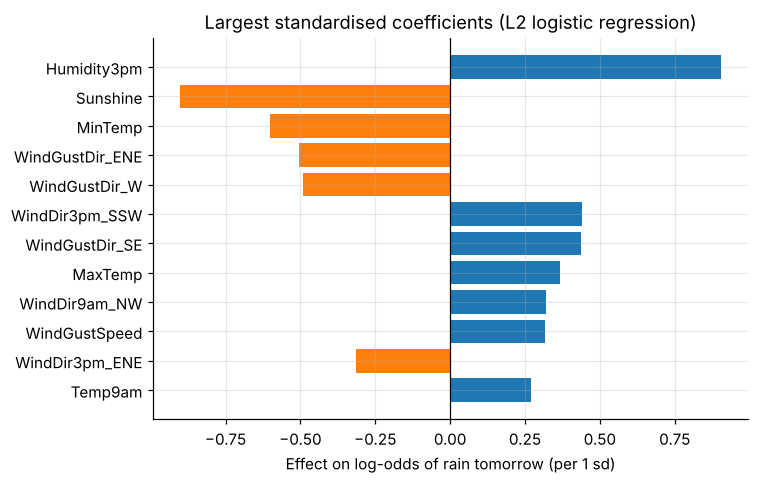

In [14]:
top = coef.sort_values(key=np.abs, ascending=False).head(12)[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top.index, top.values, color=np.where(top.values > 0, "tab:blue", "tab:orange"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Largest standardised coefficients (L2 logistic regression)")
plt.xlabel("Effect on log-odds of rain tomorrow (per 1 sd)")
plt.tight_layout(); save("t5_coefficients"); plt.show()

**Interpretation**

* Cross-validation picks **C = 0.1 (λ = 10)**, i.e. fairly strong shrinkage, which is reasonable with 60 correlated features (two pressures, four temperatures, 45 wind dummies).
* The **two strongest predictors are Humidity3pm (+0.90) and Sunshine (−0.90)**.
  * *Humidity3pm*: afternoon air already near saturation needs little extra cooling or lifting overnight to produce rain.
  * *Sunshine*: many sunshine hours mean clear skies under a stable high-pressure system, which rarely gives rain the next day. Few sunshine hours mean cloud cover, often with an approaching front.
* **The brief's hypothesis is partly confirmed.** Humidity3pm is the top predictor, as expected. RainToday (+0.22, persistence) and Pressure3pm (−0.14) have the expected signs but smaller weights. Sunshine is complete in Sydney (unlike at many stations) and carries much of the "cloudy, unsettled" signal that pressure would otherwise provide. The L2 penalty also spreads weight across the correlated Pressure9am and Pressure3pm.

## Task 6 — Evaluation and choosing a decision threshold

Hold-out metrics first. Then a threshold is chosen for the cost $C\cdot\text{FN} + 1\cdot\text{FP}$, with $C\in\{1,3,5\}$
(e.g. *harvest planning*: a missed rain day ruins cut hay, so a false negative costs several times a false alarm).

To keep the test set honest, the threshold is selected on **out-of-fold predictions on the training set** and only then applied to the test set.

In [15]:
p_te = clf.predict_proba(X_te)[:, 1]
auc_roc, auc_pr = roc_auc_score(y_te, p_te), average_precision_score(y_te, p_te)

def cm_table(y, pred):
    return pd.DataFrame(confusion_matrix(y, pred), index=["actual: dry", "actual: rain"],
                        columns=["pred: dry", "pred: rain"])

print(f"AUC-ROC = {auc_roc:.4f}")
print(f"AUC-PR  = {auc_pr:.4f}  (no-skill baseline = positive rate {y_te.mean():.4f})")
pred05 = (p_te >= 0.5).astype(int)
print(f"Threshold 0.5: precision {precision_score(y_te, pred05):.3f}, recall {recall_score(y_te, pred05):.3f}, "
      f"F1 {f1_score(y_te, pred05):.3f}")
cm_table(y_te, pred05)

AUC-ROC = 0.8580
AUC-PR  = 0.7327  (no-skill baseline = positive rate 0.2590)
Threshold 0.5: precision 0.763, recall 0.520, F1 0.619


,pred: dry,pred: rain
actual: dry,467,28
actual: rain,83,90


In [16]:
# Out-of-fold probabilities on the training set, with C fixed at the CV optimum
oof_model = make_pipeline(LogisticRegression(C=best_C, max_iter=5000))
p_oof = cross_val_predict(oof_model, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
def sweep(y, p):
    rows = []
    for t in thresholds:
        pr = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pr).ravel()
        rows.append({"threshold": t, "precision": precision_score(y, pr, zero_division=0),
                     "recall": recall_score(y, pr), "F1": f1_score(y, pr), "FP": fp, "FN": fn,
                     **{f"cost C={c}": c * fn + fp for c in (1, 3, 5)}})
    return pd.DataFrame(rows).set_index("threshold")

sw_train, sw_test = sweep(y_tr, p_oof), sweep(y_te, p_te)
chosen = {c: sw_train[f"cost C={c}"].idxmin() for c in (1, 3, 5)}

summary = pd.DataFrame({
    c: {"threshold (chosen on train OOF)": t,
        "test precision": sw_test.loc[t, "precision"], "test recall": sw_test.loc[t, "recall"],
        "test F1": sw_test.loc[t, "F1"], "test FP": sw_test.loc[t, "FP"], "test FN": sw_test.loc[t, "FN"],
        "test cost": sw_test.loc[t, f"cost C={c}"],
        "test cost at t=0.5": sw_test.loc[0.5, f"cost C={c}"]}
    for c, t in chosen.items()}).T
summary.index = [f"C = {c}" for c in chosen]
summary.round(3)

,threshold (chosen on train OOF),test precision,test recall,test F1,test FP,test FN,test cost,test cost at t=0.5
C = 1,0.53,0.777,0.503,0.611,25.0,86.0,111.0,111.0
C = 3,0.21,0.530,0.775,0.629,119.0,39.0,236.0,277.0
C = 5,0.20,0.527,0.792,0.633,123.0,36.0,303.0,443.0


Confusion matrix on the test set at the C=3 threshold (0.21):


,pred: dry,pred: rain
actual: dry,376,119
actual: rain,39,134


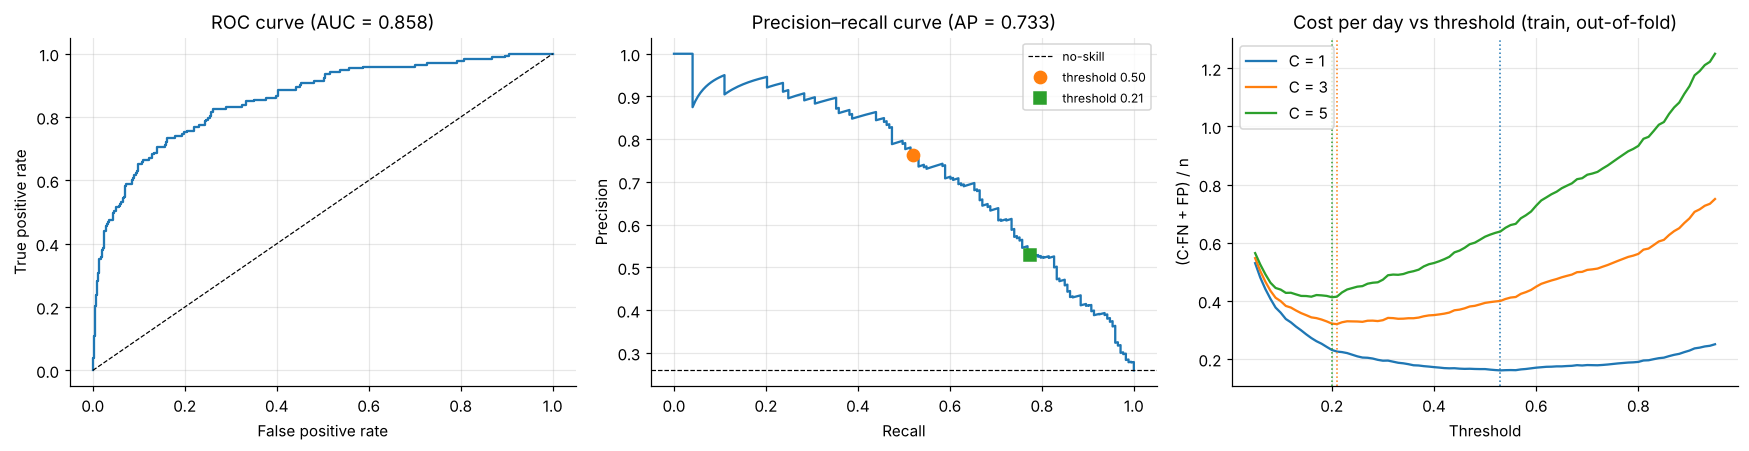

In [17]:
t3 = chosen[3]
print(f"Confusion matrix on the test set at the C=3 threshold ({t3:.2f}):")
display(cm_table(y_te, (p_te >= t3).astype(int)))

prec, rec, _ = precision_recall_curve(y_te, p_te)
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title=f"ROC curve (AUC = {auc_roc:.3f})", xlabel="False positive rate", ylabel="True positive rate")
ax[1].plot(rec, prec); ax[1].axhline(y_te.mean(), color="k", ls="--", lw=0.8, label="no-skill")
for t, mk in [(0.5, "o"), (t3, "s")]:
    ax[1].plot(sw_test.loc[t, "recall"], sw_test.loc[t, "precision"], mk, ms=8, label=f"threshold {t:.2f}")
ax[1].set(title=f"Precision–recall curve (AP = {auc_pr:.3f})", xlabel="Recall", ylabel="Precision")
ax[1].legend(fontsize=8)
for c in (1, 3, 5):
    ax[2].plot(thresholds, sw_train[f"cost C={c}"] / len(y_tr), label=f"C = {c}")
    ax[2].axvline(chosen[c], ls=":", lw=1, color=ax[2].lines[-1].get_color())
ax[2].set(title="Cost per day vs threshold (train, out-of-fold)", xlabel="Threshold", ylabel="(C·FN + FP) / n")
ax[2].legend()
plt.tight_layout(); save("t6_evaluation"); plt.show()

**Interpretation**

* **AUC-ROC = 0.858**: given a random rainy and a random dry next day, the model ranks the rainy one higher 86% of the time. **AUC-PR = 0.733**, against a no-skill baseline of 0.259 (2.8× better).
* At the default **threshold 0.5** the model is cautious: it detects only **52% of rain days** (83 missed), while 76% of its rain alerts are correct.
* **Cost-weighted thresholds.** These are chosen on out-of-fold training predictions and then checked once on the test set:
  * **C = 1** (FN and FP cost the same): the optimal threshold is 0.53, essentially the default.
  * **C = 3** (a missed rain day costs 3× a false alarm, e.g. harvest planning): the optimal threshold is **0.21**. Recall rises from 52% to **77%** (39 instead of 83 missed rain days), at the price of more false alarms (119 instead of 28). The test-set cost falls from 277 to 236 (−15%).
  * **C = 5**: the threshold is 0.20 and the cost falls by 32% against 0.5.
* **Business point:** the model's probabilities do not change. Only the decision rule does, and it should be set by what each kind of error costs the user. *Irrigation scheduling*, where both errors cost about the same, should use a threshold near 0.5. *Hay harvesting* should use one near 0.2.

## Task 7 — AIC vs BIC for nested logistic models

* **M1:** RainTomorrow ~ Humidity3pm + Pressure3pm
* **M2:** M1 + WindSpeed3pm + WindGustSpeed (WindGustSpeed substitutes for Cloud3pm, as allowed by the brief)

Both models are fitted by unpenalised maximum likelihood on the **same** complete-case sample.

* **AIC** $= -2\ell(\hat\theta) + 2k$ — an estimate of expected Kullback–Leibler loss on new data; the $2k$ term corrects the optimism of the in-sample log-likelihood.
* **BIC** $= -2\ell(\hat\theta) + k\log n$ — from a Laplace approximation to the marginal likelihood $p(\text{data}\mid M)$; the $k\log n$ term grows with the sample size.

BIC penalises each extra parameter more than AIC whenever $\log n > 2$, i.e. $n > e^2 \approx 7.4$.

In [18]:
cols7 = ["RainTomorrow", "Humidity3pm", "Pressure3pm", "WindSpeed3pm", "WindGustSpeed"]
d7 = syd[cols7].dropna()
y7 = d7["RainTomorrow"].astype(int).to_numpy()
n7 = len(d7)

res7 = {}
for name, feats in {"M1": cols7[1:3], "M2": cols7[1:]}.items():
    Xs = StandardScaler().fit_transform(d7[feats])
    fit = sm.Logit(y7, sm.add_constant(Xs)).fit(disp=0)
    k = fit.params.size
    res7[name] = {"k": k, "logL": fit.llf, "AIC": -2 * fit.llf + 2 * k, "BIC": -2 * fit.llf + k * np.log(n7)}
    assert np.isclose(res7[name]["AIC"], fit.aic) and np.isclose(res7[name]["BIC"], fit.bic)

t7 = pd.DataFrame(res7).T
t7.loc["Δ (M2 − M1)"] = t7.loc["M2"] - t7.loc["M1"]
print(f"n = {n7} complete-case days")
print(f"Penalty per extra parameter: AIC 2, BIC log(n) = {np.log(n7):.3f}  (×{np.log(n7)/2:.2f})")
print(f"Penalty for the 2 extra parameters: AIC {2*2}, BIC {2*np.log(n7):.2f}")
t7.round(2)

n = 2282 complete-case days
Penalty per extra parameter: AIC 2, BIC log(n) = 7.733  (×3.87)
Penalty for the 2 extra parameters: AIC 4, BIC 15.47


,k,logL,AIC,BIC
M1,3.0,-1005.74,2017.48,2034.67
M2,5.0,-942.78,1895.55,1924.22
Δ (M2 − M1),2.0,62.96,-121.92,-110.46


**Interpretation** (n = 2,282)

* Adding wind (M2) improves the log-likelihood by 63 units. **ΔAIC = −121.9 and ΔBIC = −110.5**, so both criteria clearly prefer M2.
* **BIC penalises more heavily**: log(2,282) = 7.73 per parameter against 2 for AIC (3.9× heavier). For the two extra parameters, the penalty is 15.5 against 4, a difference of 11.5 units. The gain in fit (126 units of −2ℓ) is far larger than either penalty, so the two criteria agree.
* **Meteorologically:** humidity and pressure together describe the synoptic situation (moist air plus low pressure means an unstable, rain-prone air mass). Wind speed and gusts add information about approaching fronts and southerly changes. The improvement is real, but it builds on the signal the two-variable model already captures.

## Task 8 — Weather regimes with a Gaussian mixture model

GMM on standardised (MaxTemp, Humidity3pm) with diagonal covariances $\Sigma_k = \operatorname{diag}(\sigma_{k1}^2, \sigma_{k2}^2)$, fitted by EM:

* **E-step:** responsibilities $r_{ik} = \dfrac{\pi_k\,\mathcal N(x_i\mid\mu_k,\Sigma_k)}{\sum_j \pi_j\,\mathcal N(x_i\mid\mu_j,\Sigma_j)}$
* **M-step:** with $N_k = \sum_i r_{ik}$: $\ \pi_k = N_k/n$, $\ \mu_k = \frac{1}{N_k}\sum_i r_{ik}x_i$, $\ \sigma_{kd}^2 = \frac{1}{N_k}\sum_i r_{ik}(x_{id}-\mu_{kd})^2$

K ∈ {2, 3, 4} is chosen by BIC (10 initialisations each).

In [19]:
d8 = syd[["MaxTemp", "Humidity3pm", "RainTomorrow"]].dropna().copy()
sc8 = StandardScaler()
Z8 = sc8.fit_transform(d8[["MaxTemp", "Humidity3pm"]])

gmms = {K: GaussianMixture(K, covariance_type="diag", n_init=10, random_state=SEED).fit(Z8) for K in (2, 3, 4)}
bic8 = pd.Series({K: m.bic(Z8) for K, m in gmms.items()}, name="BIC")
best_K = int(bic8.idxmin()); gmm = gmms[best_K]
print(bic8.round(1).to_string()); print(f"Best K by BIC: {best_K}")

SEASON = {12: "DJF summer", 1: "DJF summer", 2: "DJF summer", 3: "MAM autumn", 4: "MAM autumn", 5: "MAM autumn",
          6: "JJA winter", 7: "JJA winter", 8: "JJA winter", 9: "SON spring", 10: "SON spring", 11: "SON spring"}
d8["season"] = d8.index.month.map(SEASON)
d8["cluster"] = gmm.predict(Z8)

centres = pd.DataFrame(sc8.inverse_transform(gmm.means_), columns=["MaxTemp (°C)", "Humidity3pm (%)"])
centres["weight"] = gmm.weights_
centres["P(rain tomorrow)"] = d8.groupby("cluster")["RainTomorrow"].mean().astype(float)
centres.round(3)

2    18791.8
3    18753.2
4    18226.2
Best K by BIC: 4


,MaxTemp (°C),Humidity3pm (%),weight,P(rain tomorrow)
0,25.612,59.172,0.376,0.205
1,20.210,42.920,0.310,0.100
2,19.827,71.829,0.224,0.671
3,29.763,33.602,0.089,0.129


season,DJF summer,JJA winter,MAM autumn,SON spring
cluster,,,,
0,568,28,458,299
1,37,543,212,262
2,89,267,168,142
3,84,7,52,106


RainTomorrow,0,1
cluster,,
0,1075,278
1,949,105
2,219,447
3,217,32


ARI(cluster, season)       = 0.1407
ARI(cluster, RainTomorrow) = 0.1058


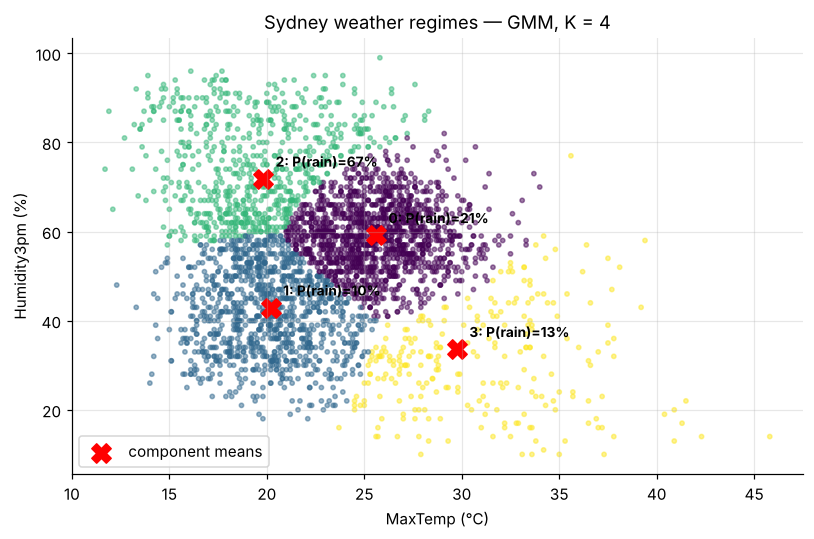

In [20]:
ct_season = pd.crosstab(d8["cluster"], d8["season"])
ct_rain = pd.crosstab(d8["cluster"], d8["RainTomorrow"].astype(int))
display(ct_season, ct_rain)
print(f"ARI(cluster, season)       = {adjusted_rand_score(d8['season'], d8['cluster']):.4f}")
print(f"ARI(cluster, RainTomorrow) = {adjusted_rand_score(d8['RainTomorrow'].astype(int), d8['cluster']):.4f}")

plt.figure(figsize=(7.5, 5))
sc = plt.scatter(d8["MaxTemp"], d8["Humidity3pm"], c=d8["cluster"], cmap="viridis", s=8, alpha=0.5)
plt.scatter(centres["MaxTemp (°C)"], centres["Humidity3pm (%)"], c="red", s=160, marker="X", label="component means")
for k, r in centres.iterrows():
    plt.annotate(f"{k}: P(rain)={r['P(rain tomorrow)']:.0%}", (r["MaxTemp (°C)"], r["Humidity3pm (%)"]),
                 xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")
plt.xlabel("MaxTemp (°C)"); plt.ylabel("Humidity3pm (%)")
plt.title(f"Sydney weather regimes — GMM, K = {best_K}"); plt.legend(loc="lower left")
plt.tight_layout(); save("t8_gmm_regimes"); plt.show()

**Interpretation**

* BIC decreases steadily and selects **K = 4**, not the K = 3 of the brief's hypothesis. The four regimes:

| component | MaxTemp | Humidity3pm | share | P(rain tomorrow) | dominant seasons | regime |
|---|---|---|---|---|---|---|
| 2 | 19.8 °C | 72% | 22% | **67%** | winter / autumn | **cool-wet** (frontal weather) |
| 0 | 25.6 °C | 59% | 38% | 21% | summer / autumn | warm-humid (typical summer day) |
| 1 | 20.2 °C | 43% | 31% | 10% | winter / spring | **cool-dry** (clear winter high) |
| 3 | 29.8 °C | 34% | 9% | 13% | summer / spring | **hot-dry** (westerly heatwave) |

* The brief's three regimes all appear: hot-dry, warm-humid and cool-wet. The fourth, **cool-dry**, splits the cool days into a rainy group and a dry one. This split matters because cool-dry days carry the lowest rain risk (10%) and cool-wet days the highest (67%).
* **ARI with season = 0.14 and with RainTomorrow = 0.11.** Both values are low, which is expected because seasons overlap in (MaxTemp, Humidity) and rain depends on more than two variables. Still, without ever seeing the labels, the GMM isolates a component in which rain follows on two days out of three. In practice it works as a rough risk stratification.

## Task 9 — Probability of an extreme rain day (> 50 mm)

$P(X > 50) = 1 - F_\Gamma(50;\hat\alpha,\hat\beta)$, using the moment estimates from Task 2 as the brief specifies (MLE shown for comparison).

**Monte Carlo.** $\hat p_{MC} = \frac1N\sum_i \mathbb 1(X_i>50)$ is an average of i.i.d. Bernoulli(p) indicators, so
$\operatorname{Var}(\hat p_{MC}) = p(1-p)/N$ and $\operatorname{SE} = \sqrt{p(1-p)/N}$ — the error shrinks like $1/\sqrt N$.

In [21]:
rng = np.random.default_rng(SEED)
N = 100_000
p_exact = stats.gamma.sf(50, a=a_mom, scale=1 / b_mom)
draws = stats.gamma.rvs(a=a_mom, scale=1 / b_mom, size=N, random_state=rng)
p_mc = (draws > 50).mean()
se_mc = np.sqrt(p_mc * (1 - p_mc) / N)

print(f"Gamma (MoM) analytic P(X>50) = {p_exact:.4%}")
print(f"Monte Carlo (N={N:,})       = {p_mc:.4%}  ± {se_mc:.4%} (1 SE);  |error| = {abs(p_mc-p_exact)/se_mc:.2f} SE")

tail = pd.DataFrame({thr: {"empirical": (wet > thr).mean(),
                           "Gamma MoM": stats.gamma.sf(thr, a=a_mom, scale=1 / b_mom),
                           "Gamma MLE": stats.gamma.sf(thr, a=a_mle, scale=1 / b_mle),
                           "rain days observed": int((wet > thr).sum())}
                     for thr in (10, 20, 50, 100)}).T
tail.index.name = "threshold (mm)"
tail["MoM / empirical"] = tail["Gamma MoM"] / tail["empirical"]
tail.round(4)

Gamma (MoM) analytic P(X>50) = 3.8197%
Monte Carlo (N=100,000)       = 3.8070%  ± 0.0605% (1 SE);  |error| = 0.21 SE


,empirical,Gamma MoM,Gamma MLE,rain days observed,MoM / empirical
threshold (mm),,,,,
10,0.3661,0.3959,0.4514,317.0,1.0817
20,0.1917,0.2094,0.2046,166.0,1.0926
50,0.0416,0.0382,0.0191,36.0,0.9188
100,0.0035,0.0027,0.0004,3.0,0.7871


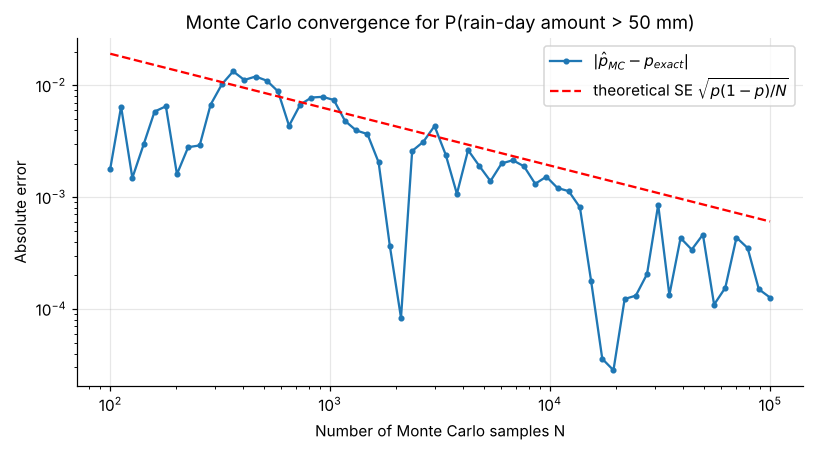

In [22]:
Ns = np.unique(np.logspace(2, 5, 60).astype(int))
err = [abs((draws[:m] > 50).mean() - p_exact) for m in Ns]
plt.figure(figsize=(7.5, 4.2))
plt.loglog(Ns, err, "o-", ms=3, label=r"$|\hat p_{MC} - p_{exact}|$")
plt.loglog(Ns, np.sqrt(p_exact * (1 - p_exact) / Ns), "r--", label=r"theoretical SE $\sqrt{p(1-p)/N}$")
plt.xlabel("Number of Monte Carlo samples N"); plt.ylabel("Absolute error")
plt.title("Monte Carlo convergence for P(rain-day amount > 50 mm)"); plt.legend()
plt.tight_layout(); save("t9_mc_convergence"); plt.show()

**Interpretation**

* Under the Gamma (MoM) model, **P(rain day > 50 mm) = 3.82%**, about 1 in 26 rain days, or roughly 3.3 days a year in Sydney. Monte Carlo with N = 100,000 gives 3.81% ± 0.06%, only 0.2 SE away from the exact value. The convergence plot follows the theoretical $\sqrt{p(1-p)/N}$ line, confirming the $1/\sqrt N$ rate.
* **Compared with the data** (empirical 4.16%, 36 of 866 rain days), the Gamma MoM underestimates the > 50 mm tail by about 8% and the > 100 mm tail by about 21%, and it overestimates moderate thresholds (10–20 mm). The discrepancy at 50 mm is within sampling error (the empirical SE ≈ 0.7 percentage points with only 36 exceedances), but the direction is consistent: **the real tail is heavier than the Gamma**.
* The Gamma **MLE** fits the bulk of the data better but halves the 50 mm probability (1.9%). A model fitted to typical days does not describe extremes.
* **Why:** the heaviest Sydney rainfalls come from East Coast Lows, a different physical population from ordinary frontal rain. A single Gamma averages both populations. For flood or insurance risk, the right tool is extreme-value theory (e.g. a generalised Pareto distribution above a high threshold).

## Task 10 — Time series of daily rainfall

The daily series is put on a complete calendar. **Days with no record stay missing** rather than being set to 0 mm —
filling them with zeros would invent dry days. The state-space ARIMA/SARIMA implementation handles missing values directly.

Caveat from the brief: daily rainfall is zero-inflated, so an ARIMA on raw amounts treats zeros as ordinary values and produces non-Gaussian residuals and impossible negative forecasts. Two approaches are shown: **(a)** a naive daily ARIMA (baseline) and **(b)** monthly rain-day counts with a seasonal SARIMA(1,0,1)(1,0,1)₁₂.

Calendar days 3,433, observed 3,331, missing 102; zero-rain days 60.7%
ADF statistic = -40.877, p = 0.00e+00, lags = 0, critical values: 1% -3.43, 5% -2.86, 10% -2.57


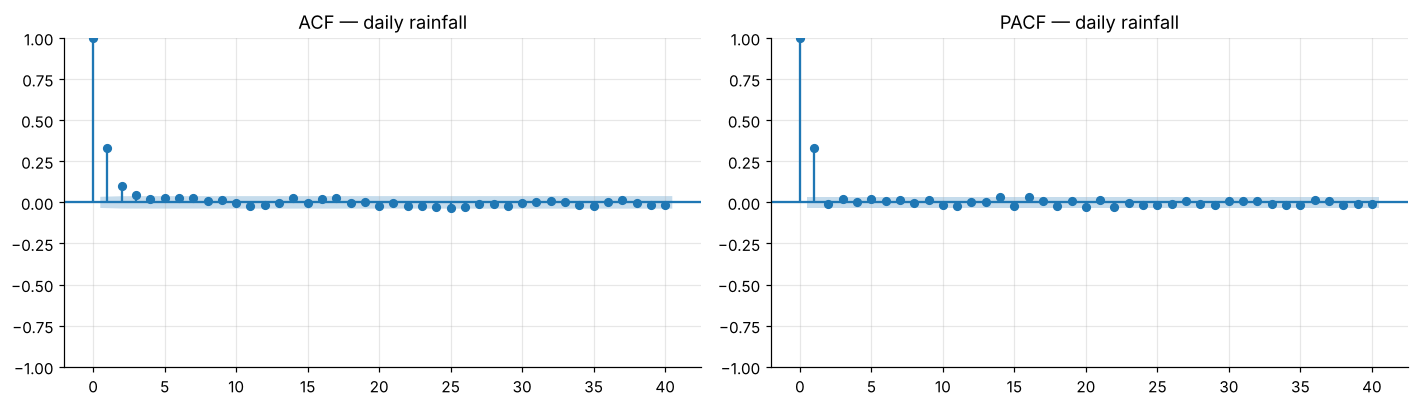

In [23]:
daily = syd["Rainfall"].asfreq("D")
obs = daily.dropna()
print(f"Calendar days {len(daily):,}, observed {len(obs):,}, missing {daily.isna().sum()}; zero-rain days {(obs == 0).mean():.1%}")

adf = adfuller(obs.to_numpy(), autolag="AIC")
print(f"ADF statistic = {adf[0]:.3f}, p = {adf[1]:.2e}, lags = {adf[2]}, "
      f"critical values: " + ", ".join(f"{k} {v:.2f}" for k, v in adf[4].items()))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(obs.to_numpy(), lags=40, ax=ax[0]); ax[0].set_title("ACF — daily rainfall")
plot_pacf(obs.to_numpy(), lags=40, ax=ax[1], method="ywm"); ax[1].set_title("PACF — daily rainfall")
plt.tight_layout(); save("t10_acf_pacf"); plt.show()

Test window 2017-05-27 → 2017-06-25 (30 observed days)
MAE: ARIMA(2,0,2) 7.17 mm vs. constant long-run mean 7.25 mm
Share of forecast days whose 95% PI goes below 0 mm: 100%


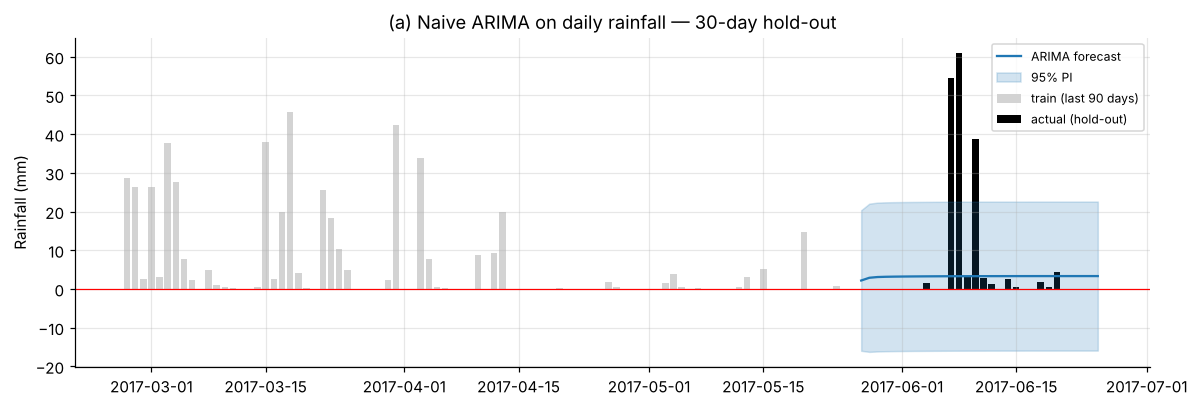

In [24]:
H = 30
train_d, test_d = daily.iloc[:-H], daily.iloc[-H:]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    arima = ARIMA(train_d, order=(2, 0, 2)).fit()
fc = arima.get_forecast(H)
pred_d, pi_d = fc.predicted_mean, fc.conf_int()

mask = test_d.notna()
mae_arima = np.mean(np.abs(test_d[mask] - pred_d.clip(lower=0)[mask]))
mae_clim = np.mean(np.abs(test_d[mask] - train_d.mean()))
print(f"Test window {test_d.index.min().date()} → {test_d.index.max().date()} ({mask.sum()} observed days)")
print(f"MAE: ARIMA(2,0,2) {mae_arima:.2f} mm vs. constant long-run mean {mae_clim:.2f} mm")
print(f"Share of forecast days whose 95% PI goes below 0 mm: {(pi_d.iloc[:, 0] < 0).mean():.0%}")

recent = train_d.iloc[-90:]
plt.figure(figsize=(11, 3.8))
plt.bar(recent.index, recent.values, color="lightgray", label="train (last 90 days)")
plt.bar(test_d.index, test_d.values, color="black", label="actual (hold-out)")
plt.plot(pred_d.index, pred_d.values, color="tab:blue", label="ARIMA forecast")
plt.fill_between(pi_d.index, pi_d.iloc[:, 0], pi_d.iloc[:, 1], color="tab:blue", alpha=0.2, label="95% PI")
plt.axhline(0, color="red", lw=0.8)
plt.ylabel("Rainfall (mm)"); plt.title("(a) Naive ARIMA on daily rainfall — 30-day hold-out"); plt.legend(fontsize=8)
plt.tight_layout(); save("t10_arima_daily"); plt.show()

Monthly series: 113 months, 3 treated as missing


,MAE (rain days),RMSE (rain days)
"SARIMA(1,0,1)(1,0,1)12",2.484,3.491
seasonal naive (same month last year),2.833,3.697
monthly climatology (train mean by month),2.796,3.875


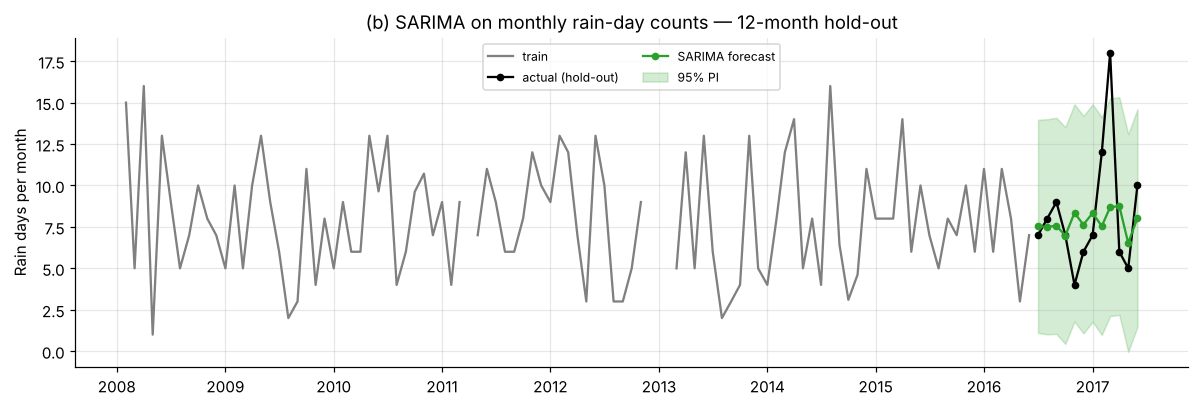

In [25]:
# (b) Monthly rain-day counts. Months with gaps are rescaled to a full month;
#     months with fewer than 20 observed days are treated as missing.
is_rain = (obs > RAIN_MM).astype(float).reindex(daily.index)
g = is_rain.resample("MS")
counts = g.mean() * g.size()          # rain-day fraction × calendar days in month
counts[g.count() < 20] = np.nan
print(f"Monthly series: {len(counts)} months, {counts.isna().sum()} treated as missing")

Hm = 12
train_m, test_m = counts.iloc[:-Hm], counts.iloc[-Hm:]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sar = SARIMAX(train_m, order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False)
fcm = sar.get_forecast(Hm)
pred_m, pi_m = fcm.predicted_mean, fcm.conf_int()

baselines = {
    "SARIMA(1,0,1)(1,0,1)12": pred_m,
    "seasonal naive (same month last year)": train_m.iloc[-12:].set_axis(test_m.index),
    "monthly climatology (train mean by month)": train_m.groupby(train_m.index.month).mean()
                                                   .reindex(test_m.index.month).set_axis(test_m.index),
}
mm = test_m.notna()
t10 = pd.DataFrame({name: {"MAE (rain days)": np.mean(np.abs(test_m[mm] - p[mm])),
                           "RMSE (rain days)": np.sqrt(np.mean((test_m[mm] - p[mm])**2))}
                    for name, p in baselines.items()}).T
display(t10.round(3))

plt.figure(figsize=(11, 3.8))
plt.plot(train_m.index, train_m.values, color="gray", label="train")
plt.plot(test_m.index, test_m.values, "ko-", ms=4, label="actual (hold-out)")
plt.plot(pred_m.index, pred_m.values, "o-", color="tab:green", ms=4, label="SARIMA forecast")
plt.fill_between(pi_m.index, pi_m.iloc[:, 0], pi_m.iloc[:, 1], color="tab:green", alpha=0.2, label="95% PI")
plt.ylabel("Rain days per month"); plt.title("(b) SARIMA on monthly rain-day counts — 12-month hold-out")
plt.legend(fontsize=8, ncol=2); plt.tight_layout(); save("t10_sarima_monthly"); plt.show()

**Interpretation**

* **ADF = −40.9 (p ≈ 0)**: the daily series is stationary, with no trend and no unit root. Dependence is short-range. The ACF is 0.33 at lag 1 and close to 0 after lag 3, and the PACF has a single spike at lag 1. Wet days cluster into short spells, consistent with an AR(1)-like occurrence process, and there is no memory beyond a few days.
* **(a) Daily ARIMA.** The forecast quickly flattens to the long-run mean of ≈ 3.3 mm per day. Its MAE (7.17 mm) is hardly better than the constant mean (7.25 mm). **Every forecast day's 95% interval extends below 0 mm**, and the model cannot represent the 55–61 mm storm days in mid-June. This illustrates the brief's caveat: ARIMA is the wrong tool for a zero-inflated, intermittent series.
* **(b) Monthly rain-day counts with SARIMA.** Aggregating to monthly counts removes the zeros and exposes the annual cycle. Over the last 12 months, SARIMA has an **MAE of 2.48 rain days per month**, better than a seasonal naive forecast (2.83) and the monthly climatology (2.80). The forecast is still fairly flat (6.5–8.7 rain days per month), because the seasonal signal in rain-day counts is small compared with the month-to-month noise. It cannot anticipate the exceptionally wet March 2017 (18 rain days), which accounts for most of the error.
* **Limits of a 30-day forecast:** daily rain in Sydney is driven by synoptic events (fronts, East Coast Lows) that are predictable only a few days ahead, and year-to-year variation is modulated by ENSO. A univariate time-series model has no access to either. Useful daily forecasts need current atmospheric state variables, which is what the Task 5 classifier uses.

## Task 11 — Does a Sydney model work in other climates?

The Task 5 pipeline (trained on Sydney only) is applied to:
the Sydney hold-out set (in-distribution baseline) and **all** records from Darwin (tropical monsoon), Perth (Mediterranean) and Alice Springs (arid).
Then a model is retrained on Darwin data and both models are compared on the same Darwin hold-out set.

In [26]:
def station_xy(name):
    X, y = make_xy(df[df["Location"] == name].set_index("Date"))
    return X.reindex(columns=X_syd.columns, fill_value=0.0), y   # align one-hot columns with Sydney

def metrics(y, p, thr=0.5):
    pr = (p >= thr).astype(int)
    return {"n": len(y), "rain rate": y.mean(), "mean predicted P": p.mean(), "AUC-ROC": roc_auc_score(y, p), "AUC-PR": average_precision_score(y, p),
            "precision": precision_score(y, pr, zero_division=0), "recall": recall_score(y, pr), "F1": f1_score(y, pr)}

rows11 = {"Sydney (hold-out)": metrics(y_te, p_te)}
station_data = {}
for st in ["Darwin", "Perth", "AliceSprings"]:
    Xs, ys = station_xy(st)
    station_data[st] = (Xs, ys)
    rows11[st] = metrics(ys, clf.predict_proba(Xs)[:, 1])

t11 = pd.DataFrame(rows11).T
t11["AUC drop vs Sydney"] = t11.loc["Sydney (hold-out)", "AUC-ROC"] - t11["AUC-ROC"]
t11.round(3)

,n,rain rate,mean predicted P,AUC-ROC,AUC-PR,precision,recall,F1,AUC drop vs Sydney
Sydney (hold-out),668.0,0.259,0.249,0.858,0.733,0.763,0.520,0.619,0.000
Darwin,3192.0,0.267,0.234,0.908,0.801,0.812,0.541,0.649,-0.050
Perth,3193.0,0.202,0.176,0.887,0.729,0.830,0.425,0.562,-0.030
AliceSprings,3031.0,0.081,0.095,0.886,0.584,0.639,0.414,0.502,-0.028


In [27]:
# Local model for Darwin, evaluated on a Darwin hold-out set alongside the Sydney model
Xd, yd = station_data["Darwin"]
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.20, stratify=yd, random_state=SEED)
darwin_clf = make_pipeline(LogisticRegressionCV(Cs=np.logspace(-4, 2, 25), cv=cv, l1_ratios=(0.0,),
                                                scoring="neg_log_loss", max_iter=5000)).fit(Xd_tr, yd_tr)

t11b = pd.DataFrame({
    "Sydney-trained model": metrics(yd_te, clf.predict_proba(Xd_te)[:, 1]),
    "Darwin-trained model": metrics(yd_te, darwin_clf.predict_proba(Xd_te)[:, 1]),
}).T
display(t11b.round(3))

# Why: compare the humidity–rain relationship in the two climates
hum = pd.concat([df[df["Location"] == s][["Humidity3pm", "RainTomorrow"]].dropna().assign(station=s)
                 for s in ["Sydney", "Darwin", "Perth", "AliceSprings"]])
hum["RainTomorrow"] = hum["RainTomorrow"].astype(int)
display(hum.groupby(["station", "RainTomorrow"])["Humidity3pm"].median().unstack()
           .rename(columns={0: "median Humidity3pm, dry next day", 1: "median Humidity3pm, rain next day"}))

,n,rain rate,mean predicted P,AUC-ROC,AUC-PR,precision,recall,F1
Sydney-trained model,639.0,0.268,0.224,0.889,0.771,0.860,0.503,0.635
Darwin-trained model,639.0,0.268,0.265,0.919,0.823,0.779,0.702,0.738


RainTomorrow,"median Humidity3pm, dry next day","median Humidity3pm, rain next day"
station,,
AliceSprings,18.0,53.0
Darwin,46.0,69.0
Perth,44.0,63.0
Sydney,52.0,67.0


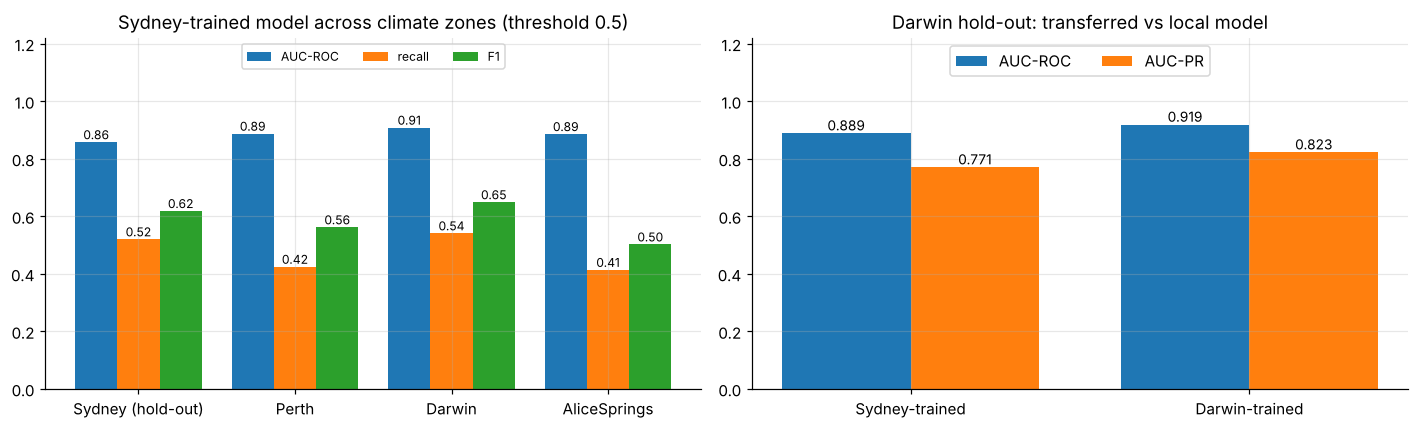

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = ["Sydney (hold-out)", "Perth", "Darwin", "AliceSprings"]
xo = np.arange(len(order)); w3 = 0.27
for j, (m, col) in enumerate([("AUC-ROC", "tab:blue"), ("recall", "tab:orange"), ("F1", "tab:green")]):
    vals = t11.loc[order, m]
    ax[0].bar(xo + (j - 1) * w3, vals, w3, label=m, color=col)
    for i, v in enumerate(vals):
        ax[0].text(i + (j - 1) * w3, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(xo, order); ax[0].set(ylim=(0, 1.22), title="Sydney-trained model across climate zones (threshold 0.5)")
ax[0].legend(loc="upper center", ncol=3, fontsize=8)
lab = ["Sydney-trained", "Darwin-trained"]
x_ = np.arange(2); w = 0.38
ax[1].bar(x_ - w/2, t11b["AUC-ROC"], w, label="AUC-ROC")
ax[1].bar(x_ + w/2, t11b["AUC-PR"], w, label="AUC-PR")
for i in range(2):
    ax[1].text(i - w/2, t11b["AUC-ROC"].iloc[i] + 0.01, f"{t11b['AUC-ROC'].iloc[i]:.3f}", ha="center", fontsize=9)
    ax[1].text(i + w/2, t11b["AUC-PR"].iloc[i] + 0.01, f"{t11b['AUC-PR'].iloc[i]:.3f}", ha="center", fontsize=9)
ax[1].set_xticks(x_, lab); ax[1].set(ylim=(0, 1.22), title="Darwin hold-out: transferred vs local model")
ax[1].legend(loc="upper center", ncol=2)
plt.tight_layout(); save("t11_transfer"); plt.show()

**Interpretation — the brief's hypothesis is refuted, but transfer still costs something**

* **Ranking ability transfers well.** The Sydney-trained model reaches AUC-ROC 0.89–0.91 at Darwin, Perth and Alice Springs, *higher* than on Sydney itself (0.86). The brief expected a drop of 0.10–0.20. The reason: the physical signal (afternoon humidity relative to that day's conditions, sunshine, pressure) points the same way everywhere. Rain-prone days are relatively humid and cloudy in every climate, and those stations are also easier to predict than Sydney (sharper wet/dry seasons in Darwin, mostly dry days in Alice Springs).
* **What fails is calibration and the threshold.** The decision boundary learned in Sydney sits in the wrong place for other climates. The median Humidity3pm before a rain day is 67% in Sydney but 53% in Alice Springs, where dry days sit at 18%. At threshold 0.5, recall falls to 0.41–0.43 at Perth and Alice Springs, and F1 falls to 0.50–0.56 (Sydney: 0.62). In Alice Springs (8% rain rate), AUC-PR drops to 0.58.
* Calibration shifts too. The Sydney model's mean predicted probability is 0.23 in Darwin against an actual rain rate of 0.27, and 0.18 in Perth against 0.20, so it systematically under-forecasts rain in those climates.
* **A local model is clearly better.** On the same Darwin hold-out set, retraining on Darwin raises AUC-ROC from 0.889 to 0.919, AUC-PR from 0.771 to 0.823, recall from 0.50 to 0.70 and **F1 from 0.635 to 0.738 (+16%)**.
* **Strategies for production:** (a) one model per climate zone (Köppen), the standard approach in operational forecasting; (b) a hierarchical model with station-specific intercepts and slopes that shares strength within a zone; (c) climatology meta-features (mean annual rainfall, mean humidity) so that a single model knows where it is. At minimum, **recalibrate the threshold per station**, since the ranking is already good.